# Extra Trees Hyperparameter Search

## 1. Objective

The objective of this notebook is to tune an Extra Trees regressor for predicting restaurant `weighted_rating`, using a 15-trial Bayesian search scored by 5-fold cross-validation. Completed trials are checkpointed so the search can resume after interruption.

The best settings are then validated with 5 folds and refit on the full training split, so they can be used as one member of the ensemble.

## 2. Problem Statement

The task is the same as in `Baseline_Model_Training.ipynb`: predict the weighted rating of a restaurant from the prepared cuisine, location, menu, pricing and geographical features.

**Target Variable:** `weighted_rating`

**Problem Type:** Supervised Machine Learning - Regression

## 3. Evaluation Metrics

- Cross-validation RMSE on the training rows. This is the only score the search sees.
- MAE, RMSE and R² of the best settings, as the mean and standard deviation over the 5 folds.

## 4. How the Search Works

Fifteen configurations are tried, and each new one is chosen using what the earlier ones scored.

1. **Random start.** The first 3 configurations are random, because a model fitted on one or two results knows nothing yet.
2. **Learn from the results.** A Gaussian process is fitted to every (settings, score) pair so far. For a new setting it predicts a score and how unsure that prediction is.
3. **Pick the next setting.** Candidate settings are scored with expected improvement (how much better than the current best a candidate is likely to be) and the best candidate is trained and scored next. The exploration factor is `XI = 0.002`.

This is the same method as in `XGBoost_Hyperparameter_Search.ipynb` and `LightGBM_Hyperparameter_Search.ipynb`.

## 5. How the Data Is Used

- Only the training split is loaded. **The test set is not loaded in this notebook at all**, so it cannot influence any choice.
- Settings are chosen on the mean 5-fold validation RMSE (`KFold`, shuffled, seed 42, the same folds as the other notebooks).
- After the search, the best settings are validated again with 5 folds, giving per-fold MAE, RMSE and R². The out-of-fold predictions are saved for the ensemble notebook.
- Finally the best settings are refit on the full training split (all folds added back together).

## 6. How to Run

- Requirements: `scikit-learn`, `scipy`, `pandas`, `numpy`, `matplotlib`.
- One trial is 5 cross-validation fits. Extra Trees fits are heavier than XGBoost or LightGBM: in `Ensemble_4_Models.ipynb` a 500-tree Random Forest took about 1 minute per fit, so a trial can take a few minutes.
- The trials run in three cells: 1-5, 6-10 and 11-15. The last cell completes any trials left over from the earlier cells.
- Any cell can be interrupted. Finished trials are kept and the next run continues from them.
- A 90-minute time limit stops the search on a very slow machine.

## 7. Expected Outcome

A set of tuned Extra Trees settings with a validation score (mean ± std over 5 folds) that can be compared with the other tuned models. For reference, the default Extra Trees in the baseline notebook (200 trees) scored RMSE 0.13404 on a single 80/20 validation split.

## Step 1: Imports and Configuration

Paths follow the other notebooks: prepared data is read from `data/processed`. All search settings are kept in the block at the top of the next cell.

In [1]:
import os
import time
import json
import warnings
import pickle
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel

from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# ================================ CONFIG ================================
DATA_DIR = Path("data/processed")        # prepared datasets from the EDA notebook
OUT_DIR = Path("outputs/extra_trees")    # everything this notebook saves
OUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
CV_FOLDS = 5

N_TRIALS = 15                  # total configurations to try
N_WARMUP = 3                   # first trials are random, the rest are chosen by the model

EXPLORE_XI = 0.002             # exploration factor in expected improvement
N_POOL = 4000                  # candidates drawn over the whole space
N_LOCAL = 3000                 # candidates drawn around the current best
LOCAL_SCALE = 0.20             # how wide that neighbourhood is
KERNEL_RESTARTS = 2
TIME_LIMIT_MIN = 90            # safety stop, so a run always ends

BASELINE_REF = {"MAE": 0.09892, "RMSE": 0.13404, "R2": 0.37088}   # default Extra Trees, Baseline notebook
# ========================================================================

print("Data folder :", DATA_DIR)
print(f"Budget      : {N_TRIALS} trials x {CV_FOLDS} folds")
print(f"Search      : Gaussian process + expected improvement (xi = {EXPLORE_XI})")

Data folder : data\processed
Budget      : 15 trials x 5 folds
Search      : Gaussian process + expected improvement (xi = 0.002)


## Step 2: Load the Training Data

Only the training files are loaded: encoded and imputed features plus the `weighted_rating` target. The cell stops with a clear message if a file is missing.

In [2]:
FILES = ["X_train_processed.csv", "y_train.csv"]
missing = [f for f in FILES if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in '{DATA_DIR}'. Run the EDA / preprocessing notebook first, "
        "or set DATA_DIR to the folder that holds these prepared files."
    )

X_train = pd.read_csv(DATA_DIR / "X_train_processed.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze("columns")

print(f"Train      {X_train.shape}")
print("Missing values:", int(X_train.isna().sum().sum()))
print(f"Target      mean {y_train.mean():.4f} | std {y_train.std():.4f}")

Train      (53574, 263)
Missing values: 0
Target      mean 3.9372 | std 0.1699


## Step 3: Search Space

Each setting is mapped to a number between 0 and 1, because the Gaussian process needs all settings on a common scale. The numbers are converted back into valid Extra Trees settings before a model is trained.

| Setting | Range | Type | What it does |
|---|---|---|---|
| `n_estimators` | 200 - 500 | one of four choices | number of trees |
| `max_depth` | 10 - 40 | integer | how deep each tree can grow |
| `min_samples_split` | 2 - 20 | integer | fewest rows a node needs before it can split |
| `min_samples_leaf` | 1 - 10 | integer | fewest rows a leaf may hold (higher gives smoother predictions) |
| `max_features` | 0.3 - 1.0 | continuous | share of features tried at each split |

The baseline Extra Trees had no depth limit. The upper limit of 40 stands in for that, since the Gaussian process needs a number.

In [3]:
class SearchSpace:
    """Turns a vector of numbers in [0, 1] into real hyperparameter values."""

    def __init__(self, dims):
        self.dims = dims

    @property
    def names(self):
        return [name for name, _, _ in self.dims]

    @property
    def d(self):
        return len(self.dims)

    def decode(self, u):
        params = {}
        for (name, kind, spec), value in zip(self.dims, np.clip(u, 0.0, 1.0)):
            if kind == "choice":
                params[name] = spec[int(round(value * (len(spec) - 1)))]
            elif kind == "int":
                lo, hi = spec
                params[name] = int(round(lo + value * (hi - lo)))
            elif kind == "log":
                lo, hi = spec
                params[name] = float(10 ** (np.log10(lo) + value * (np.log10(hi) - np.log10(lo))))
            elif kind == "linear":
                lo, hi = spec
                params[name] = float(lo + value * (hi - lo))
            else:
                raise ValueError(kind)
        return params

    def encode(self, params):
        u = []
        for name, kind, spec in self.dims:
            value = params[name]
            if kind == "choice":
                u.append(spec.index(value) / (len(spec) - 1))
            elif kind == "int" or kind == "linear":
                lo, hi = spec
                u.append((value - lo) / (hi - lo))
            elif kind == "log":
                lo, hi = spec
                u.append((np.log10(value) - np.log10(lo)) / (np.log10(hi) - np.log10(lo)))
        return np.array(u, dtype=float)

    def signature(self, params):
        return tuple(sorted(params.items()))


SPACE = SearchSpace([
    ("n_estimators", "choice", [200, 300, 400, 500]),
    ("max_depth", "int", (10, 40)),
    ("min_samples_split", "int", (2, 20)),
    ("min_samples_leaf", "int", (1, 10)),
    ("max_features", "linear", (0.3, 1.0)),
])

print("Settings:", SPACE.d, SPACE.names)

Settings: 5 ['n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features']


## Step 4: Scoring One Configuration

One function scores one configuration. It runs 5-fold cross-validation on the training rows, with the same folds every time, and returns the mean RMSE. This number is the only feedback the search gets. A configuration that fails is scored 1.0 instead of stopping the run, and a configuration that was already scored is answered from a cache.

In [4]:
def make_model(**params):
    return ExtraTreesRegressor(random_state=RANDOM_STATE, n_jobs=-1, **params)


cv_folds = list(KFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X_train))
CACHE = {}


def cv_score(params):
    """Mean 5-fold CV RMSE, its spread across folds, and the time it took."""
    key = tuple(sorted(params.items()))
    if key in CACHE:
        rmse, std, _ = CACHE[key]
        return rmse, std, 0.0

    t0 = time.time()
    try:
        scores = []
        for tr_idx, va_idx in cv_folds:
            model = make_model(**params)
            model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
            pred = model.predict(X_train.iloc[va_idx])
            scores.append(float(np.sqrt(mean_squared_error(y_train.iloc[va_idx], pred))))
        out = (float(np.mean(scores)), float(np.std(scores)), time.time() - t0)
    except Exception as exc:
        print(f"    fit failed ({type(exc).__name__}) - scored as 1.0")
        out = (1.0, 0.0, time.time() - t0)

    CACHE[key] = out
    return out


def fresh_params(rng, tried):
    """A random configuration the search has not tried yet."""
    for _ in range(1000):
        params = SPACE.decode(rng.uniform(0, 1, SPACE.d))
        if SPACE.signature(params) not in tried:
            return params
    return SPACE.decode(rng.uniform(0, 1, SPACE.d))


CHECKPOINT_PATH = OUT_DIR / "search_checkpoint.pkl"
SEARCH_CONFIG = {
    "n_trials": N_TRIALS,
    "n_warmup": N_WARMUP,
    "cv_folds": CV_FOLDS,
    "random_state": RANDOM_STATE,
    "space": SPACE.dims,
}

STATE = {"history": [], "tried": set(), "best_params": None,
         "best_rmse": float("inf"), "rng": np.random.RandomState(RANDOM_STATE + 1),
         "start": None}


def save_checkpoint():
    """Persist completed trials and RNG state after each trial."""
    payload = {
        "config": SEARCH_CONFIG,
        "history": STATE["history"],
        "tried": list(STATE["tried"]),
        "best_params": STATE["best_params"],
        "best_rmse": STATE["best_rmse"],
        "rng_state": STATE["rng"].get_state(),
    }
    fd, temp_path = tempfile.mkstemp(
        prefix="extra_trees_checkpoint_", suffix=".tmp", dir=OUT_DIR
    )
    try:
        with os.fdopen(fd, "wb") as f:
            pickle.dump(payload, f, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(temp_path, CHECKPOINT_PATH)
    finally:
        if os.path.exists(temp_path):
            os.remove(temp_path)


def load_checkpoint():
    """Restore a compatible checkpoint; otherwise start a fresh search."""
    if not CHECKPOINT_PATH.exists():
        print("No search checkpoint found; starting a new search.")
        return
    with open(CHECKPOINT_PATH, "rb") as f:
        payload = pickle.load(f)
    if payload.get("config") != SEARCH_CONFIG:
        raise ValueError(
            "The saved Extra Trees checkpoint uses a different search configuration. "
            "Move/delete the checkpoint in outputs/extra_trees to start a fresh search."
        )
    STATE["history"] = payload["history"]
    STATE["tried"] = {tuple(x) for x in payload["tried"]}
    STATE["best_params"] = payload["best_params"]
    STATE["best_rmse"] = payload["best_rmse"]
    STATE["rng"].set_state(payload["rng_state"])
    print(f"Resumed checkpoint: {len(STATE['history'])}/{N_TRIALS} trials already complete.")


load_checkpoint()
print("Folds ready:", len(cv_folds))

Folds ready: 5


## Step 5: The Bayesian Search

`propose_next()` chooses the next configuration (random during the warm-up, then by expected improvement) and `run_trials(n)` runs up to `n` new trials. Each completed trial is saved to `outputs/extra_trees/search_checkpoint.pkl`, so an interrupted search can resume in a fresh kernel.

In [5]:
def expected_improvement(mu, sd, best, xi=EXPLORE_XI):
    """How much better than the current best a candidate is expected to be."""
    sd = np.maximum(sd, 1e-9)
    z = (best - mu - xi) / sd
    return (best - mu - xi) * norm.cdf(z) + sd * norm.pdf(z)


def fit_gp(history):
    X_obs = np.array([SPACE.encode(h) for h in history])
    y_obs = np.array([h["cv_rmse"] for h in history])
    kernel = (ConstantKernel(1.0, (1e-2, 1e2))
              * Matern(length_scale=np.ones(SPACE.d), length_scale_bounds=(1e-2, 1e2), nu=2.5)
              + WhiteKernel(1e-3, (1e-6, 1e-1)))
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                                  n_restarts_optimizer=KERNEL_RESTARTS,
                                  random_state=RANDOM_STATE)
    gp.fit(X_obs, y_obs)
    return gp


def propose_next():
    """Random while warming up, then the candidate with the highest expected improvement."""
    rng, history = STATE["rng"], STATE["history"]

    if len(history) < N_WARMUP:
        return fresh_params(rng, STATE["tried"]), "random", np.nan, np.nan

    try:
        gp = fit_gp(history)
    except Exception:
        return fresh_params(rng, STATE["tried"]), "random", np.nan, np.nan

    wide = rng.uniform(0, 1, (N_POOL, SPACE.d))
    local = np.clip(SPACE.encode(STATE["best_params"])
                    + rng.normal(0, LOCAL_SCALE, (N_LOCAL, SPACE.d)), 0, 1)
    candidates = np.vstack([wide, local])

    mu, sd = gp.predict(candidates, return_std=True)
    score = expected_improvement(mu, sd, STATE["best_rmse"])
    seen = np.array([SPACE.signature(SPACE.decode(c)) in STATE["tried"] for c in candidates])
    score = np.where(seen, -np.inf, score)

    if not np.isfinite(score).any():
        return fresh_params(rng, STATE["tried"]), "random", np.nan, np.nan

    i = int(np.argmax(score))
    return SPACE.decode(candidates[i]), "aimed", float(mu[i]), float(sd[i])


def show_history():
    if not STATE["history"]:
        print("No trials yet.")
        return
    df = pd.DataFrame(STATE["history"])
    cols = ["trial", "method", "pred_mean", "cv_rmse", "fold_std", "best_so_far", "secs"] + SPACE.names
    display(df[cols].round(5).style
            .highlight_min(subset=["cv_rmse"], color="lightgreen")
            .set_caption(f"Trials so far ({len(df)}/{N_TRIALS})"))


def run_trials(n):
    """Run up to n new trials. Interrupting is safe - finished trials are kept."""
    if STATE["start"] is None:
        STATE["start"] = time.time()
    done = 0
    while done < n and len(STATE["history"]) < N_TRIALS:
        if (time.time() - STATE["start"]) / 60 > TIME_LIMIT_MIN:
            print(f"Time limit of {TIME_LIMIT_MIN} minutes reached.")
            break

        params, method, pred_mean, pred_sd = propose_next()
        STATE["tried"].add(SPACE.signature(params))
        rmse, std, secs = cv_score(params)

        improved = rmse < STATE["best_rmse"]
        if improved:
            STATE["best_params"], STATE["best_rmse"] = params, rmse

        trial = len(STATE["history"]) + 1
        STATE["history"].append({"trial": trial, "method": method, "pred_mean": pred_mean,
                                 "pred_std": pred_sd, "cv_rmse": rmse, "fold_std": std,
                                 "secs": secs, "best_so_far": STATE["best_rmse"], **params})
        save_checkpoint()
        print(f"trial {trial:2d}/{N_TRIALS} | RMSE {rmse:.5f} (std {std:.5f}) "
              f"| best {STATE['best_rmse']:.5f} | {method:6s} | {secs:.0f}s"
              + ("   <- new best" if improved else ""))
        done += 1

    show_history()

## Step 6: Run the Trials

The 15 trials run in three cells. Run them in order.

### Trials 1-5

Run this cell. Each completed trial is checkpointed and can be resumed after an interruption.

In [6]:
run_trials(5)

trial  1/15 | RMSE 0.13411 (std 0.00096) | best 0.13411 | random | 96s   <- new best
trial  2/15 | RMSE 0.13393 (std 0.00104) | best 0.13393 | random | 372s   <- new best
trial  3/15 | RMSE 0.13394 (std 0.00102) | best 0.13393 | random | 264s
trial  4/15 | RMSE 0.13448 (std 0.00100) | best 0.13393 | aimed  | 120s
trial  5/15 | RMSE 0.13930 (std 0.00112) | best 0.13393 | aimed  | 67s


,trial,method,pred_mean,cv_rmse,fold_std,best_so_far,secs,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features
0,1,random,nan,0.134110,0.000960,0.134110,95.550210,200,28,4,3,0.529000
1,2,random,nan,0.133930,0.001040,0.133930,371.804590,500,30,12,1,0.813620
2,3,random,nan,0.133940,0.001020,0.133930,264.451530,300,34,7,2,0.906650
3,4,aimed,0.134030,0.134480,0.001000,0.133930,120.333880,500,28,10,3,0.300000
4,5,aimed,0.134120,0.139300,0.001120,0.133930,66.653770,300,12,11,6,0.518240


### Trials 6-10

Run this cell next. The search resumes from the latest saved checkpoint if it was interrupted.

In [7]:
run_trials(5)

trial  6/15 | RMSE 0.13399 (std 0.00105) | best 0.13393 | aimed  | 373s
trial  7/15 | RMSE 0.13676 (std 0.00113) | best 0.13393 | aimed  | 63s
trial  8/15 | RMSE 0.13496 (std 0.00109) | best 0.13393 | aimed  | 278s
trial  9/15 | RMSE 0.13425 (std 0.00103) | best 0.13393 | aimed  | 80s
trial 10/15 | RMSE 0.13522 (std 0.00114) | best 0.13393 | aimed  | 264s


,trial,method,pred_mean,cv_rmse,fold_std,best_so_far,secs,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features
0,1,random,nan,0.134110,0.000960,0.134110,95.550210,200,28,4,3,0.529000
1,2,random,nan,0.133930,0.001040,0.133930,371.804590,500,30,12,1,0.813620
2,3,random,nan,0.133940,0.001020,0.133930,264.451530,300,34,7,2,0.906650
3,4,aimed,0.134030,0.134480,0.001000,0.133930,120.333880,500,28,10,3,0.300000
4,5,aimed,0.134120,0.139300,0.001120,0.133930,66.653770,300,12,11,6,0.518240
5,6,aimed,0.134350,0.133990,0.001050,0.133930,372.765330,500,40,20,1,0.947860
6,7,aimed,0.137670,0.136760,0.001130,0.133930,63.079990,200,18,16,10,0.491720
7,8,aimed,0.138280,0.134960,0.001090,0.133930,277.959820,500,26,5,8,0.819400
8,9,aimed,0.133910,0.134250,0.001030,0.133930,80.098690,200,40,9,4,0.503030
9,10,aimed,0.134480,0.135220,0.001140,0.133930,264.499610,400,35,12,10,0.979430


### Trials 11-15

The last cell completes any trials left over from the earlier cells.

In [8]:
run_trials(N_TRIALS)

trial 11/15 | RMSE 0.13463 (std 0.00095) | best 0.13393 | aimed  | 358s
trial 12/15 | RMSE 0.13400 (std 0.00101) | best 0.13393 | aimed  | 145s
trial 13/15 | RMSE 0.13473 (std 0.00084) | best 0.13393 | aimed  | 246s
trial 14/15 | RMSE 0.13403 (std 0.00109) | best 0.13393 | aimed  | 263s
trial 15/15 | RMSE 0.13434 (std 0.00103) | best 0.13393 | aimed  | 364s


,trial,method,pred_mean,cv_rmse,fold_std,best_so_far,secs,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features
0,1,random,nan,0.134110,0.000960,0.134110,95.550210,200,28,4,3,0.529000
1,2,random,nan,0.133930,0.001040,0.133930,371.804590,500,30,12,1,0.813620
2,3,random,nan,0.133940,0.001020,0.133930,264.451530,300,34,7,2,0.906650
3,4,aimed,0.134030,0.134480,0.001000,0.133930,120.333880,500,28,10,3,0.300000
4,5,aimed,0.134120,0.139300,0.001120,0.133930,66.653770,300,12,11,6,0.518240
5,6,aimed,0.134350,0.133990,0.001050,0.133930,372.765330,500,40,20,1,0.947860
6,7,aimed,0.137670,0.136760,0.001130,0.133930,63.079990,200,18,16,10,0.491720
7,8,aimed,0.138280,0.134960,0.001090,0.133930,277.959820,500,26,5,8,0.819400
8,9,aimed,0.133910,0.134250,0.001030,0.133930,80.098690,200,40,9,4,0.503030
9,10,aimed,0.134480,0.135220,0.001140,0.133930,264.499610,400,35,12,10,0.979430


## Step 7: Best Settings

The winner is the configuration with the lowest mean 5-fold validation RMSE. The plot shows every trial and the best score so far.

Trials finished : 15/15
Best CV RMSE    : 0.13393
Search time     : 55.9 minutes

Best settings:
  n_estimators       500
  max_depth          30
  min_samples_split  12
  min_samples_leaf   1
  max_features       0.8136238073961981


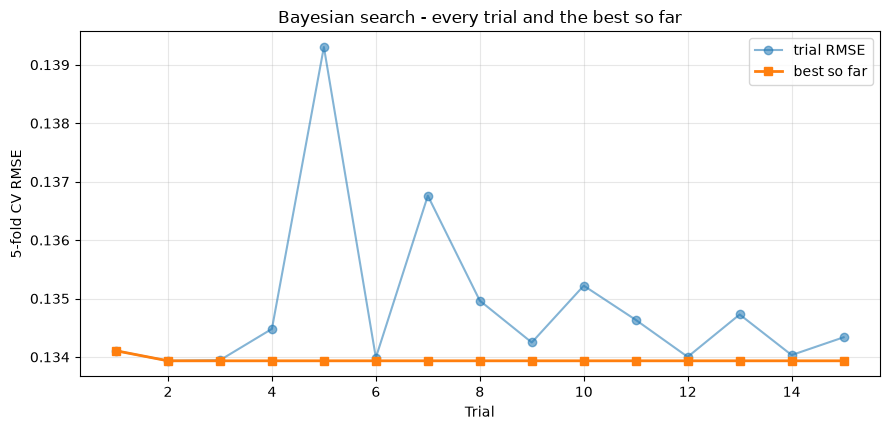

In [9]:
history = pd.DataFrame(STATE["history"])
BEST = STATE["best_params"]

print(f"Trials finished : {len(history)}/{N_TRIALS}")
print(f"Best CV RMSE    : {STATE['best_rmse']:.5f}")
print(f"Search time     : {history.secs.sum() / 60:.1f} minutes")
print("\nBest settings:")
for name, value in BEST.items():
    print(f"  {name:18s} {value}")

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(history.trial, history.cv_rmse, marker="o", alpha=0.55, label="trial RMSE")
ax.plot(history.trial, history.best_so_far, marker="s", linewidth=2, label="best so far")
ax.set_xlabel("Trial")
ax.set_ylabel("5-fold CV RMSE")
ax.set_title("Bayesian search - every trial and the best so far")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "search_progress.png", dpi=200, bbox_inches="tight")
plt.show()

## Step 8: Validation Score of the Best Settings

The best settings are run once more through the same 5 folds, this time recording MAE, RMSE and R² for each fold. The validation score is the mean over the folds, with the standard deviation showing how much it moves between folds. The out-of-fold predictions are saved so the ensemble notebook can use them.

In [10]:
oof = np.zeros(len(y_train))
rows = []
for k, (tr_idx, va_idx) in enumerate(cv_folds, start=1):
    model = make_model(**BEST)
    model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    pred = model.predict(X_train.iloc[va_idx])
    oof[va_idx] = pred
    y_va = y_train.iloc[va_idx]
    rows.append({"Fold": k,
                 "MAE": mean_absolute_error(y_va, pred),
                 "RMSE": float(np.sqrt(mean_squared_error(y_va, pred))),
                 "R2": r2_score(y_va, pred)})

fold_df = pd.DataFrame(rows).set_index("Fold")
val_summary = pd.DataFrame({"Mean": fold_df.mean(), "Std": fold_df.std(ddof=0)})

display(fold_df.round(5).style.set_caption("Validation score per fold"))
display(val_summary.round(5).style.set_caption("Validation score: mean and std over 5 folds"))

pooled = float(np.sqrt(mean_squared_error(y_train, oof)))
print(f"Pooled out-of-fold RMSE (all training rows together): {pooled:.5f}")

np.save(OUT_DIR / "ExtraTrees_oof.npy", oof)
fold_df.to_csv(OUT_DIR / "validation_per_fold.csv")
print("Saved out-of-fold predictions and per-fold scores to", OUT_DIR)

,MAE,RMSE,R2
Fold,,,
1,0.097850,0.132750,0.382950
2,0.098730,0.135430,0.385560
3,0.099230,0.134790,0.360090
4,0.098230,0.133750,0.385810
5,0.097830,0.132940,0.376510


,Mean,Std
MAE,0.098370,0.000540
RMSE,0.133930,0.001040
R2,0.378180,0.009650


Pooled out-of-fold RMSE (all training rows together): 0.13394
Saved out-of-fold predictions and per-fold scores to outputs\extra_trees


## Step 9: Final Refit on the Full Training Split

The 5 validation folds are added back together and the best settings are fitted once on all training rows. This is the model that would be used for the final prediction. It has seen every training row, so it is **not** scored on the validation folds; the 5-fold mean above is its expected performance.

The fitted model is not saved, because a deep Extra Trees model with several hundred trees can take gigabytes of disk. The settings are saved instead, and the ensemble notebook can refit from them.

In [11]:
t0 = time.time()
final_model = make_model(**BEST)
final_model.fit(X_train, y_train)
print(f"Refit on {len(X_train):,} rows x {X_train.shape[1]} features in {time.time() - t0:.1f}s")

with open(OUT_DIR / "best_params.json", "w") as f:
    json.dump(BEST, f, indent=2)
history.to_csv(OUT_DIR / "search_trials.csv", index=False)
print("Saved best settings and the trial table to", OUT_DIR)

Refit on 53,574 rows x 263 features in 89.2s
Saved best settings and the trial table to outputs\extra_trees


## Step 10: Summary of This Run

The next cell summarizes the saved search results and five-fold validation metrics.

In [12]:
rows = []
for name, kind, spec in SPACE.dims:
    pos = float(SPACE.encode(BEST)[SPACE.names.index(name)])
    rng_text = f"{spec[0]} - {spec[-1]}"
    rows.append(f"| `{name}` | {BEST[name]:.4g} | {rng_text} | {'yes' if pos < 0.05 or pos > 0.95 else 'no'} |")

val = val_summary
aimed = history[history.method == "aimed"].cv_rmse
rand = history[history.method == "random"].cv_rmse

display(Markdown(f"""
**Search:** {len(history)} trials ({len(rand)} random, {len(aimed)} chosen by the search), {history.secs.sum() / 60:.1f} minutes.
Best trial: {int(history.loc[history.cv_rmse.idxmin(), 'trial'])}. Best CV RMSE {STATE['best_rmse']:.5f}.
Average random trial {rand.mean():.5f}, average guided trial {aimed.mean():.5f}.

| Setting | Best value | Range searched | Near the edge of the range? |
|---|---:|---|---|
{chr(10).join(rows)}

| Validation (5-fold) | MAE | RMSE | R² |
|---|---:|---:|---:|
| Mean | {val.loc['MAE','Mean']:.5f} | {val.loc['RMSE','Mean']:.5f} | {val.loc['R2','Mean']:.5f} |
| Std over folds | {val.loc['MAE','Std']:.5f} | {val.loc['RMSE','Std']:.5f} | {val.loc['R2','Std']:.5f} |
| Baseline Extra Trees, one 80/20 split | {BASELINE_REF['MAE']:.5f} | {BASELINE_REF['RMSE']:.5f} | {BASELINE_REF['R2']:.5f} |

Final refit used {len(X_train):,} training rows. The test set was not used.
"""))


**Search:** 15 trials (3 random, 12 chosen by the search), 55.9 minutes.
Best trial: 2. Best CV RMSE 0.13393.
Average random trial 0.13400, average guided trial 0.13506.

| Setting | Best value | Range searched | Near the edge of the range? |
|---|---:|---|---|
| `n_estimators` | 500 | 200 - 500 | yes |
| `max_depth` | 30 | 10 - 40 | no |
| `min_samples_split` | 12 | 2 - 20 | no |
| `min_samples_leaf` | 1 | 1 - 10 | yes |
| `max_features` | 0.8136 | 0.3 - 1.0 | no |

| Validation (5-fold) | MAE | RMSE | R² |
|---|---:|---:|---:|
| Mean | 0.09837 | 0.13393 | 0.37818 |
| Std over folds | 0.00054 | 0.00104 | 0.00965 |
| Baseline Extra Trees, one 80/20 split | 0.09892 | 0.13404 | 0.37088 |

Final refit used 53,574 training rows. The test set was not used.


## Notes and Limitations

- **The test set is not used here.** It is not even loaded. Any test score belongs in the final ensemble notebook, once, for the chosen model only.
- **The same 5 folds are used for tuning and for the validation score.** Because the settings were picked to do well on these folds, the validation score is slightly optimistic.
- **The baseline row is only a rough guide.** It comes from one 80/20 split with default settings, while the tuned row is a 5-fold mean, so the two are not measured on the same rows.
- **15 trials is small for five settings.** The result is a good region, not the exact optimum. Trials closer together than the fold-to-fold spread (the `fold_std` column) are effectively tied.
- **Check the "near the edge" column in Step 10.** If a best value sits at the edge of its range, the true best may lie outside it.
- **Extra Trees is random by design.** One seed (42) is used throughout, so small differences between runs are noise.

## Next Steps

1. Copy `outputs/extra_trees/best_params.json` into the ensemble notebook and add Extra Trees to the models being compared.
2. Compare it with the other models on out-of-fold validation error (`ExtraTrees_oof.npy`), not on test.
3. If a setting ended at the edge of its range, widen that range and search again, with more trials if time allows.